# Steel Plant Energy Consumption Forecasting

## Project Overview

This project develops a machine learning model to forecast the next interval's
energy consumption using historical energy usage, electrical measurements,
and time-based features.

## Objectives

- Explore and clean the energy consumption dataset.
- Engineer features from timestamps and historical usage.
- Train a machine learning regression model.
- Evaluate forecasting performance using MAE and RMSE.
- Visualise predictions and analyse forecasting errors.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

from IPython.display import display

pd.set_option("display.max_columns", None)

In [20]:
df = pd.read_csv("../data/train.csv")

df["date"] = pd.to_datetime(
    df["date"],
    format="%d/%m/%Y %H:%M"
)

df = df.sort_values("date").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (28031, 12)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,next_interval_Usage_kWh
0,2018-01-01 00:00:00,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load,3.20
1,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,4.00
2,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,3.24
3,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,3.31
4,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,3.82


In [21]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nTarget variable summary:")
display(df["next_interval_Usage_kWh"].describe())

print("\nLoad type distribution:")
display(df["Load_Type"].value_counts().to_frame("Count"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28031 entries, 0 to 28030
Data columns (total 12 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   date                                  28031 non-null  datetime64[ns]
 1   Usage_kWh                             28031 non-null  float64       
 2   Lagging_Current_Reactive.Power_kVarh  28031 non-null  float64       
 3   Leading_Current_Reactive_Power_kVarh  28031 non-null  float64       
 4   CO2(tCO2)                             28031 non-null  float64       
 5   Lagging_Current_Power_Factor          28031 non-null  float64       
 6   Leading_Current_Power_Factor          28031 non-null  float64       
 7   NSM                                   28031 non-null  int64         
 8   WeekStatus                            28031 non-null  object        
 9   Day_of_week                           28031 non-nul

,Missing Values
date,0
Usage_kWh,0
Lagging_Current_Reactive.Power_kVarh,0
Leading_Current_Reactive_Power_kVarh,0
CO2(tCO2),0
Lagging_Current_Power_Factor,0
Leading_Current_Power_Factor,0
NSM,0
WeekStatus,0
Day_of_week,0



Number of duplicate rows: 0

Target variable summary:


count    28031.000000
mean        27.926530
std         33.921641
min          2.450000
25%          3.130000
50%          4.610000
75%         51.260000
max        153.140000
Name: next_interval_Usage_kWh, dtype: float64


Load type distribution:


,Count
Load_Type,
Light_Load,14367
Medium_Load,7808
Maximum_Load,5856


## 4. Exploratory Data Analysis

Exploratory Data Analysis helps us understand energy consumption patterns, the distribution of the target variable, and differences between load types.


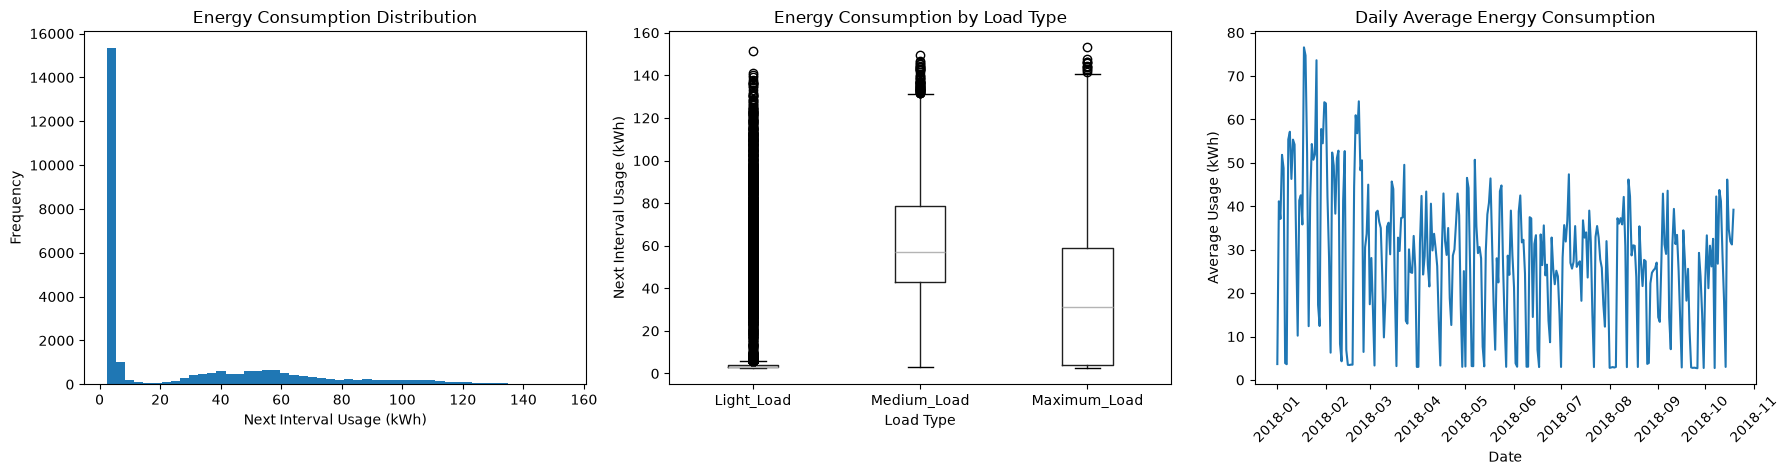

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df["next_interval_Usage_kWh"], bins=50)
axes[0].set_title("Energy Consumption Distribution")
axes[0].set_xlabel("Next Interval Usage (kWh)")
axes[0].set_ylabel("Frequency")

load_order = ["Light_Load", "Medium_Load", "Maximum_Load"]
df.boxplot(
    column="next_interval_Usage_kWh",
    by="Load_Type",
    ax=axes[1],
    grid=False
)
axes[1].set_title("Energy Consumption by Load Type")
axes[1].set_xlabel("Load Type")
axes[1].set_ylabel("Next Interval Usage (kWh)")
axes[1].set_xticklabels(load_order)

daily_usage = df.set_index("date")["Usage_kWh"].resample("D").mean()
axes[2].plot(daily_usage.index, daily_usage.values)
axes[2].set_title("Daily Average Energy Consumption")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("Average Usage (kWh)")
axes[2].tick_params(axis="x", rotation=45)

plt.suptitle("")
plt.tight_layout()
plt.show()

## 5. Feature Engineering

Feature engineering transforms raw data into meaningful inputs for machine learning.

In this project, we extract time-based features from timestamps and create lag features from historical energy consumption. These features help the model identify daily patterns and recent changes in energy usage.


In [23]:
df_model = df.copy()

df_model["hour"] = df_model["date"].dt.hour
df_model["minute"] = df_model["date"].dt.minute
df_model["day"] = df_model["date"].dt.day
df_model["month"] = df_model["date"].dt.month
df_model["day_of_year"] = df_model["date"].dt.dayofyear
df_model["day_of_week"] = df_model["date"].dt.dayofweek
df_model["is_weekend"] = (df_model["day_of_week"] >= 5).astype(int)

df_model["hour_sin"] = np.sin(2 * np.pi * df_model["hour"] / 24)
df_model["hour_cos"] = np.cos(2 * np.pi * df_model["hour"] / 24)
df_model["day_sin"] = np.sin(2 * np.pi * df_model["day_of_year"] / 365)
df_model["day_cos"] = np.cos(2 * np.pi * df_model["day_of_year"] / 365)
df_model["hour_weekend"] = df_model["hour"] * df_model["is_weekend"]

usage_by_time = df_model.set_index("date")["Usage_kWh"]

for lag, minutes in [(1, 15), (4, 60), (96, 1440)]:
    previous_time = df_model["date"] - pd.Timedelta(minutes=minutes)
    df_model[f"usage_lag_{lag}"] = previous_time.map(usage_by_time)

print("Feature engineering completed!")
print("Original columns:", df.shape[1])
print("Columns after feature engineering:", df_model.shape[1])

display(df_model.head())

Feature engineering completed!
Original columns: 12
Columns after feature engineering: 27


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,next_interval_Usage_kWh,hour,minute,day,month,day_of_year,day_of_week,is_weekend,hour_sin,hour_cos,day_sin,day_cos,hour_weekend,usage_lag_1,usage_lag_4,usage_lag_96
0,2018-01-01 00:00:00,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load,3.20,0,0,1,1,1,0,0,0.000000,1.000000,0.017213,0.999852,0,NaN,NaN,NaN
1,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,4.00,0,15,1,1,1,0,0,0.000000,1.000000,0.017213,0.999852,0,3.42,NaN,NaN
2,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,3.24,0,30,1,1,1,0,0,0.000000,1.000000,0.017213,0.999852,0,3.17,NaN,NaN
3,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,3.31,0,45,1,1,1,0,0,0.000000,1.000000,0.017213,0.999852,0,4.00,NaN,NaN
4,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,3.82,1,0,1,1,1,0,0,0.258819,0.965926,0.017213,0.999852,0,3.24,3.42,NaN


## 6. Chronological Train–Validation Split

Since this project forecasts energy consumption over time, randomly shuffling the dataset could cause data leakage. Therefore, the data is split chronologically: earlier observations are used for training, and later observations are used for validation.



In [24]:
df_model = df_model.dropna().reset_index(drop=True)

split_index = int(len(df_model) * 0.8)

train_df = df_model.iloc[:split_index].copy()
val_df = df_model.iloc[split_index:].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nValidation period:")
print(val_df["date"].min(), "to", val_df["date"].max())

Training rows: 22346
Validation rows: 5587

Training period:
2018-01-02 00:00:00 to 2018-08-22 18:15:00

Validation period:
2018-08-22 18:30:00 to 2018-10-19 23:45:00


## 7. Model Training

We use a HistGradientBoostingRegressor to predict next-interval energy consumption. The model learns from historical measurements and engineered time features.

The target is log-transformed using `log1p` to reduce the influence of highly skewed values. Predictions are converted back to the original scale using `expm1`.


In [25]:

target = "next_interval_Usage_kWh"

exclude_columns = [target, "date"]

features = [
    col for col in train_df.columns
    if col not in exclude_columns
]

categorical_features = [
    "WeekStatus",
    "Day_of_week",
    "Load_Type"
]

numeric_features = [
    col for col in features
    if col not in categorical_features
]

X_train = train_df[features]
y_train = np.log1p(train_df[target])

X_val = val_df[features]
y_val = val_df[target]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=250,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42
    ))
])

model.fit(X_train, y_train)

y_pred = np.expm1(model.predict(X_val))
y_pred = np.maximum(y_pred, 0)

print("Model training completed!")
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Number of features:", len(features))



Model training completed!
Training rows: 22346
Validation rows: 5587
Number of features: 25


## 8. Model Evaluation

We evaluate the model using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

* **MAE:** Measures the average absolute difference between actual and predicted energy consumption.
* **RMSE:** Penalises larger prediction errors more heavily.

Both metrics are calculated on the chronological validation set, which was not used to train the model.


In [26]:
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("Validation Results")
print("------------------")
print(f"MAE:  {mae:.4f} kWh")
print(f"RMSE: {rmse:.4f} kWh")

Validation Results
------------------
MAE:  3.7954 kWh
RMSE: 8.5569 kWh


## 9. Actual vs Predicted Energy Consumption

This visualisation compares actual energy consumption with the model's predictions over the validation period. It helps us identify how closely the model follows changes in energy usage.


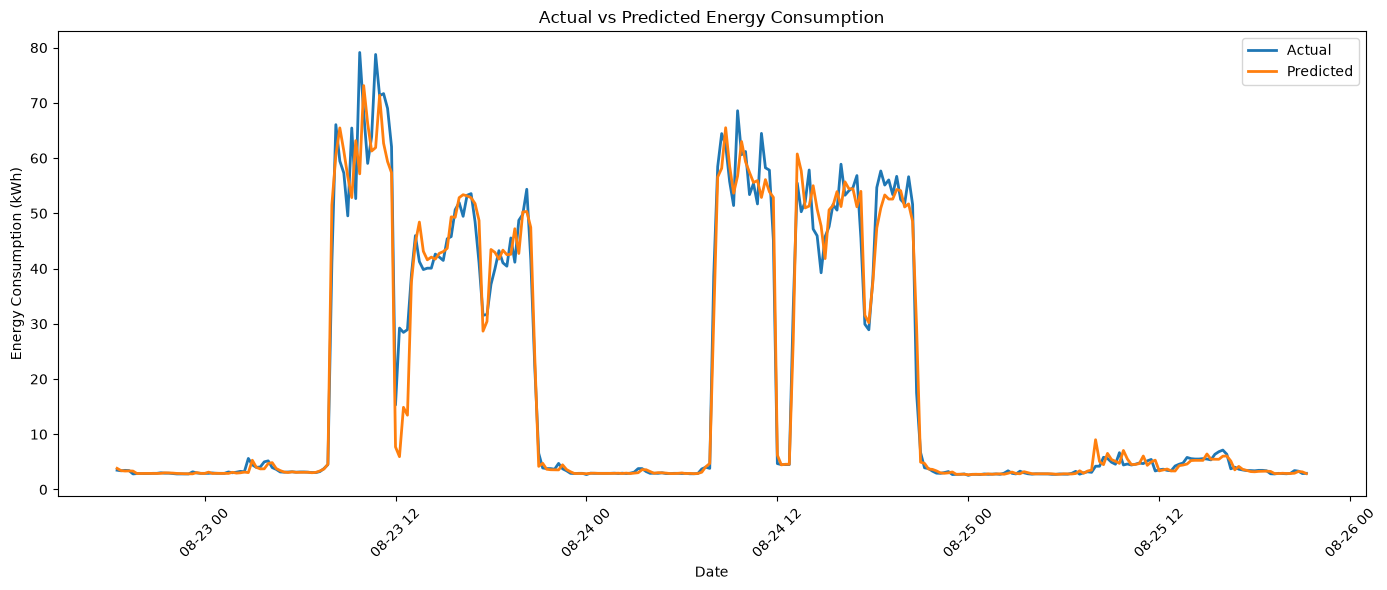

In [27]:
from pathlib import Path

Path("../plots").mkdir(exist_ok=True)

plot_n = min(300, len(val_df))

plt.figure(figsize=(14, 6))
plt.plot(
    val_df["date"].iloc[:plot_n],
    y_val.iloc[:plot_n].to_numpy(),
    label="Actual",
    linewidth=2
)
plt.plot(
    val_df["date"].iloc[:plot_n],
    y_pred[:plot_n],
    label="Predicted",
    linewidth=2
)

plt.title("Actual vs Predicted Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../plots/actual_vs_predicted_validation.png", dpi=300)
plt.show()

## 10. Error Analysis by Load Type

Energy consumption varies across light, medium, and maximum load conditions. We analyse prediction errors for each load type to identify where the model performs well and where improvements may be needed.


In [28]:
val_results = val_df[["date", "Load_Type", target]].copy()

val_results["Predicted_Usage_kWh"] = y_pred

val_results["Absolute_Error"] = np.abs(
    val_results[target] - val_results["Predicted_Usage_kWh"]
)

error_summary = val_results.groupby("Load_Type")["Absolute_Error"].agg(
    ["count", "mean", "median", "max"]
).rename(columns={"mean": "MAE", "median": "Median Error", "max": "Maximum Error"})

display(error_summary.round(4))

,count,MAE,Median Error,Maximum Error
Load_Type,,,,
Light_Load,2880,1.1689,0.1163,55.2449
Maximum_Load,1152,8.9442,5.6517,65.4913
Medium_Load,1555,4.8455,0.9755,71.2408


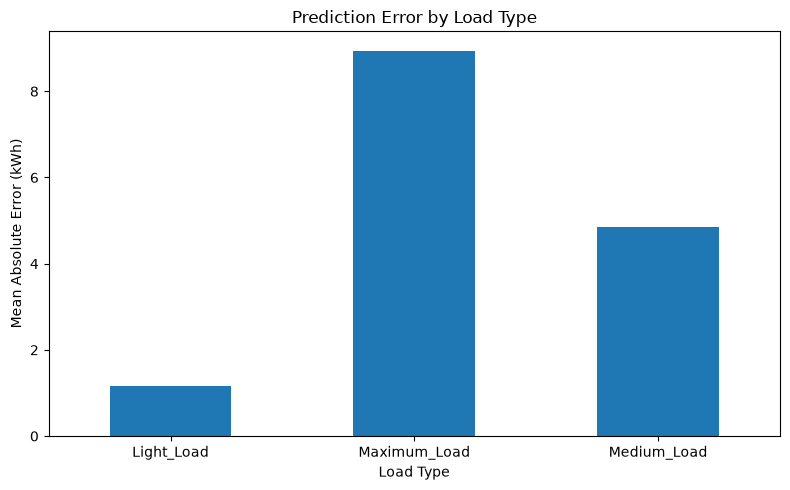

In [29]:
error_summary["MAE"].plot(kind="bar", figsize=(8, 5))

plt.title("Prediction Error by Load Type")
plt.xlabel("Load Type")
plt.ylabel("Mean Absolute Error (kWh)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../plots/error_by_load_type.png", dpi=300)
plt.show()

## 11. Conclusion

This project developed a machine learning model to forecast next-interval energy consumption in a steel plant.

The workflow included data inspection, exploratory data analysis, timestamp-based feature engineering, historical usage features, chronological train-validation splitting, and model training using a HistGradientBoostingRegressor.

The model was evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). Visualisations and load-type error analysis were used to understand prediction performance and identify areas for improvement.

This project demonstrates how machine learning can support energy monitoring and more informed energy-management decisions in industrial environments.


## 12. Saving the Final Model

After evaluating the model on the validation set, we retrain it using all available labelled data. The final model and feature names are saved for future predictions.


In [30]:
import joblib
from pathlib import Path
from sklearn.base import clone

Path("../models").mkdir(exist_ok=True)

X_all = df_model[features]
y_all = np.log1p(df_model[target])

final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", clone(model.named_steps["regressor"]))
])

final_model.fit(X_all, y_all)

joblib.dump(final_model, "../models/final_model.pkl")
joblib.dump(features, "../models/features.pkl")

print("Final model saved successfully!")
print("Model: models/final_model.pkl")
print("Features: models/features.pkl")

Final model saved successfully!
Model: models/final_model.pkl
Features: models/features.pkl
